In [45]:
import numpy as np
from scipy.optimize import curve_fit

# Data
X = np.array([[1, 1], [1, 0], [0, 1], [0, 0]])
y = np.array([0, 1, 0, 1])

# Find the best beta coefficients over all combinations of training-testing splits
def find_best_linear_model(X, y):
    
    from itertools import combinations
    best_mse = float('inf')
    best_model = None
    best_indices = None

    for indices in combinations(range(len(X)), 3):
        train_indices = list(indices)
        test_index = list(set(range(len(X))) - set(train_indices))[0]

        X_train = X[train_indices]
        y_train = y[train_indices]
        X_test = X[test_index]
        y_test = y[test_index]

        X_train_aug = np.hstack([np.ones((len(X_train), 1)), X_train]) # Add intercept
        X_test_aug = np.array([1, X_test[0], X_test[1]]).reshape(1, -1) # Add intercept

        beta = np.linalg.inv(X_train_aug.T.dot(X_train_aug)).dot(X_train_aug.T).dot(y_train)
        y_pred = X_test_aug.dot(beta)

        mse = (y_test - y_pred)**2
        if mse < best_mse:
            best_mse = mse
            best_model = beta
            best_indices = train_indices

    return best_model, best_indices, test_index

# Best linear model
best_linear_model, best_indices, test_index = find_best_linear_model(X, y)

# Best Combination of Training-testing Split
X_train = X[best_indices]
y_train = y[best_indices]
X_test = X[test_index]
y_test = y[test_index]

# Results
y_pred_linear = X_test_aug.dot(best_linear_model)
mse_linear = (y_test - y_pred_linear)**2

print("Best Beta Coefficients (Linear):", best_linear_model)
print("Testing Label vs Predicted Label:", y_test, y_pred_linear)
print("MSE for Linear Model:", mse_linear)

Best Beta Coefficients (Linear): [ 1.00000000e+00  8.32667268e-17 -1.00000000e+00]
Testing Label vs Predicted Label: 0 [0.]
MSE for Linear Model: [0.]


In [46]:
# Sigmoid function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def model(X, beta0, beta1, beta2):
    X_aug = np.hstack([np.ones((len(X), 1)), X])
    return sigmoid(beta0 + beta1 * X_aug[:, 1] + beta2 * X_aug[:, 2])

X_train_aug = np.hstack([np.ones((len(X_train), 1)), X_train])
X_test_aug = np.array([1, X_test[0], X_test[1]]).reshape(1, -1)

# Fit the nonlinear model
params, params_covariance = curve_fit(lambda X, b0, b1, b2: model(X, b0, b1, b2), X_train, y_train, p0=[0, 0, 0])

y_pred_nonlinear = model(X_test_aug.reshape(1,-1), *params)
mse_nonlinear = (y_test - y_pred_nonlinear)**2

# Results
print("Beta Coefficients (Nonlinear):", params)
print("Testing Label vs Predicted Label:", y_test, y_pred_nonlinear)
print("MSE for Nonlinear Model:", mse_nonlinear)

Beta Coefficients (Nonlinear): [ 2.20048302e+01 -8.97762403e-16 -4.52077195e+01]
Testing Label vs Predicted Label: 0 [8.37747657e-11]
MSE for Nonlinear Model: [7.01821137e-21]


/Users/jimmyzheng0516/anaconda3/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:906: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


In [47]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

X = np.array([[1, 1], [1, 0], [0, 1], [0, 0]], dtype='float32')
y = np.array([[0], [1], [0], [1]], dtype='float32')

# The training and testing sets
training_X = X[best_indices]
training_y = y[best_indices]
testing_X = X[[test_index]]
testing_y = y[[test_index]]

# Feedforward neural network model
model = Sequential()
model.add(Dense(32, input_dim=2, activation='relu'))  # Hidden layer with ReLU activation
model.add(Dense(1, activation='sigmoid'))  # Output layer with sigmoid activation

model.compile(loss='mean_squared_error', optimizer='adam', metrics=['binary_accuracy'])
model.fit(training_X, training_y, epochs=100, verbose=2)

loss, accuracy = model.evaluate(testing_X, testing_y, verbose=2)
print(f"Testing Loss: {loss}, Testing Accuracy: {accuracy}")

# Full dataset testing
full_dataset_loss, full_dataset_accuracy = model.evaluate(X, y, verbose=2)
print(f"Full Dataset Testing Loss: {full_dataset_loss}, Full Dataset Testing Accuracy: {full_dataset_accuracy}")

# Predictions for binary output
predictions = model.predict(training_X)
print("Unrounded Predictions on training set:", predictions)
rounded_predictions = np.round(predictions)
print("Rounded Predictions on Training Set:", rounded_predictions)

Epoch 1/100
1/1 - 0s - loss: 0.3177 - binary_accuracy: 0.0000e+00 - 88ms/epoch - 88ms/step
Epoch 2/100
1/1 - 0s - loss: 0.3158 - binary_accuracy: 0.0000e+00 - 1ms/epoch - 1ms/step
Epoch 3/100
1/1 - 0s - loss: 0.3138 - binary_accuracy: 0.0000e+00 - 1ms/epoch - 1ms/step
Epoch 4/100
1/1 - 0s - loss: 0.3118 - binary_accuracy: 0.0000e+00 - 2ms/epoch - 2ms/step
Epoch 5/100
1/1 - 0s - loss: 0.3100 - binary_accuracy: 0.0000e+00 - 1ms/epoch - 1ms/step
Epoch 6/100
1/1 - 0s - loss: 0.3081 - binary_accuracy: 0.0000e+00 - 2ms/epoch - 2ms/step
Epoch 7/100
1/1 - 0s - loss: 0.3062 - binary_accuracy: 0.0000e+00 - 1ms/epoch - 1ms/step
Epoch 8/100
1/1 - 0s - loss: 0.3044 - binary_accuracy: 0.0000e+00 - 1ms/epoch - 1ms/step
Epoch 9/100
1/1 - 0s - loss: 0.3025 - binary_accuracy: 0.0000e+00 - 1ms/epoch - 1ms/step
Epoch 10/100
1/1 - 0s - loss: 0.3007 - binary_accuracy: 0.0000e+00 - 2ms/epoch - 2ms/step
Epoch 11/100
1/1 - 0s - loss: 0.2989 - binary_accuracy: 0.0000e+00 - 1ms/epoch - 1ms/step
Epoch 12/100
1/1 

Epoch 95/100
1/1 - 0s - loss: 0.2013 - binary_accuracy: 0.6667 - 920us/epoch - 920us/step
Epoch 96/100
1/1 - 0s - loss: 0.2005 - binary_accuracy: 0.6667 - 947us/epoch - 947us/step
Epoch 97/100
1/1 - 0s - loss: 0.1998 - binary_accuracy: 0.6667 - 1ms/epoch - 1ms/step
Epoch 98/100
1/1 - 0s - loss: 0.1991 - binary_accuracy: 0.6667 - 1ms/epoch - 1ms/step
Epoch 99/100
1/1 - 0s - loss: 0.1983 - binary_accuracy: 0.6667 - 1ms/epoch - 1ms/step
Epoch 100/100
1/1 - 0s - loss: 0.1976 - binary_accuracy: 0.6667 - 972us/epoch - 972us/step
1/1 - 0s - loss: 0.1450 - binary_accuracy: 1.0000 - 34ms/epoch - 34ms/step
Testing Loss: 0.14501488208770752, Testing Accuracy: 1.0
1/1 - 0s - loss: 0.2416 - binary_accuracy: 0.5000 - 7ms/epoch - 7ms/step
Full Dataset Testing Loss: 0.24162136018276215, Full Dataset Testing Accuracy: 0.5
1/1 [==============================] - 0s 16ms/step
Unrounded Predictions on training set: [[0.3808082 ]
 [0.4023381 ]
 [0.46726587]]
Rounded Predictions on Training Set: [[0.]
 [0.]


In [48]:
import tensorflow as tf
import numpy as np

# Load dataset
fashion_mnist = tf.keras.datasets.fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Change labels to binary: 1 for "Shirt", 0 for "Others"
train_labels = (train_labels == 6).astype(int)
test_labels = (test_labels == 6).astype(int)

# Scale images to range from 0 to 1
train_images = train_images / 255.0
test_images = test_images / 255.0

# Feedforward neural network
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)), 
    tf.keras.layers.Dense(256, activation='relu'), 
    tf.keras.layers.Dense(128, activation='relu'), 
    tf.keras.layers.Dense(1, activation='sigmoid') 
])


model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.fit(train_images, train_labels, epochs=10, validation_split=0.1)

# Model Evaluation on Testing Data
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)

print('\nTest loss:', test_loss, 'Test accuracy:', test_acc)

# Make predictions
predictions = model.predict(test_images)

Epoch 1/10
1688/1688 [==============================] - 1s 770us/step - loss: 0.1844 - accuracy: 0.9226 - val_loss: 0.1524 - val_accuracy: 0.9347
Epoch 2/10
1688/1688 [==============================] - 1s 740us/step - loss: 0.1524 - accuracy: 0.9354 - val_loss: 0.1431 - val_accuracy: 0.9387
Epoch 3/10
1688/1688 [==============================] - 1s 752us/step - loss: 0.1432 - accuracy: 0.9399 - val_loss: 0.1382 - val_accuracy: 0.9405
Epoch 4/10
1688/1688 [==============================] - 1s 760us/step - loss: 0.1358 - accuracy: 0.9429 - val_loss: 0.1431 - val_accuracy: 0.9393
Epoch 5/10
1688/1688 [==============================] - 1s 768us/step - loss: 0.1308 - accuracy: 0.9449 - val_loss: 0.1466 - val_accuracy: 0.9347
Epoch 6/10
1688/1688 [==============================] - 1s 752us/step - loss: 0.1268 - accuracy: 0.9463 - val_loss: 0.1478 - val_accuracy: 0.9380
Epoch 7/10
1688/1688 [==============================] - 1s 746us/step - loss: 0.1231 - accuracy: 0.9475 - val_loss: 0.1361 -

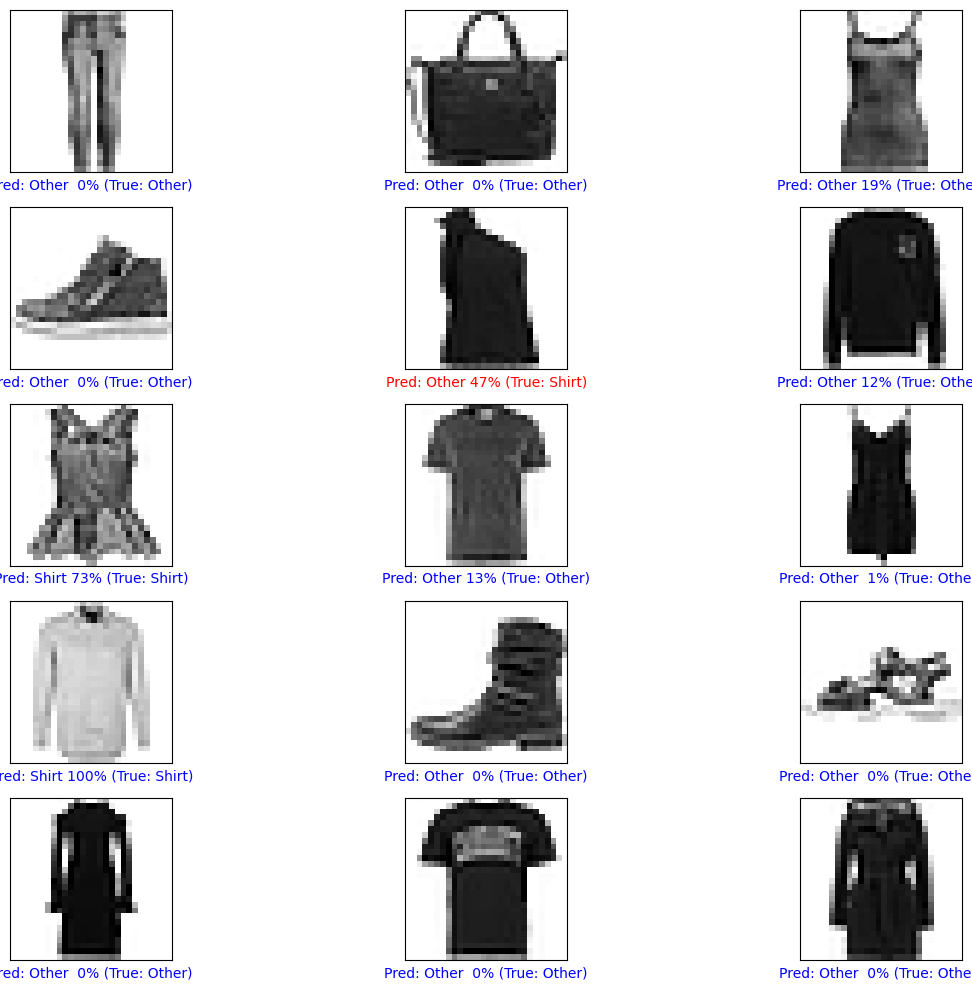

In [49]:
import matplotlib.pyplot as plt

def plot_image_with_prediction(i, predictions_array, true_label, img):
    plt.figure(figsize=(6,3))
    plt.subplot(1,2,1)
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img, cmap=plt.cm.binary)
    
    predicted_label = int(predictions_array[i] > 0.5)
    true_label = true_label[i]
    if predicted_label == true_label:
        color = 'blue'
    else:
        color = 'red'

    plt.xlabel("{} {:2.0f}% ({})".format("Shirt" if predicted_label == 1 else "Other",
                                         100 * predictions_array[i],
                                         "Shirt" if true_label == 1 else "Other"),
               color=color)

    plt.show()

# Number of images to display
num_rows = 5
num_cols = 3
num_images = num_rows * num_cols

plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
    idx = np.random.randint(0, len(test_images))  # Randomly pick an index
    plt.subplot(num_rows, 2*num_cols, 2*i+1)
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(test_images[idx], cmap=plt.cm.binary)
    predicted_label = int(predictions[idx] > 0.5)
    color = 'blue' if predicted_label == test_labels[idx] else 'red'
    plt.xlabel("Pred: {} {:2.0f}% (True: {})".format(
        "Shirt" if predicted_label == 1 else "Other",
        100 * np.max(predictions[idx]),
        "Shirt" if test_labels[idx] == 1 else "Other"),
        color=color)
plt.tight_layout()
plt.show()

In [57]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras import Sequential

# Create models by increasing the number of hidden layers
def create_model(num_layers):
    model = Sequential([Flatten(input_shape=(28, 28))])
    # Add hidden layers
    for _ in range(num_layers):
        model.add(Dense(128, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

models = {f"{i} layers": create_model(i) for i in range(1, 5)}

# Model Training
fashion_mnist = tf.keras.datasets.fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()
train_images = train_images / 255.0
test_images = test_images / 255.0
train_labels = (train_labels == 6).astype(int)
test_labels = (test_labels == 6).astype(int)

history_dict = {}
for name, model in models.items():
    print(f"Training model with {name}")
    history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels), verbose=0)
    history_dict[name] = history

# Model Evaludation
results = {}
for name, model in models.items():
    test_loss, test_accuracy = model.evaluate(test_images, test_labels, verbose=0)
    results[name] = (test_loss, test_accuracy)
    print(f"{name}: Test Loss = {test_loss:.4f}, Test Accuracy = {test_accuracy:.4f}")

Training model with 1 layers
Training model with 2 layers
Training model with 3 layers
Training model with 4 layers
1 layers: Test Loss = 0.1456, Test Accuracy = 0.9411
2 layers: Test Loss = 0.1497, Test Accuracy = 0.9410
3 layers: Test Loss = 0.1528, Test Accuracy = 0.9424
4 layers: Test Loss = 0.1668, Test Accuracy = 0.9344


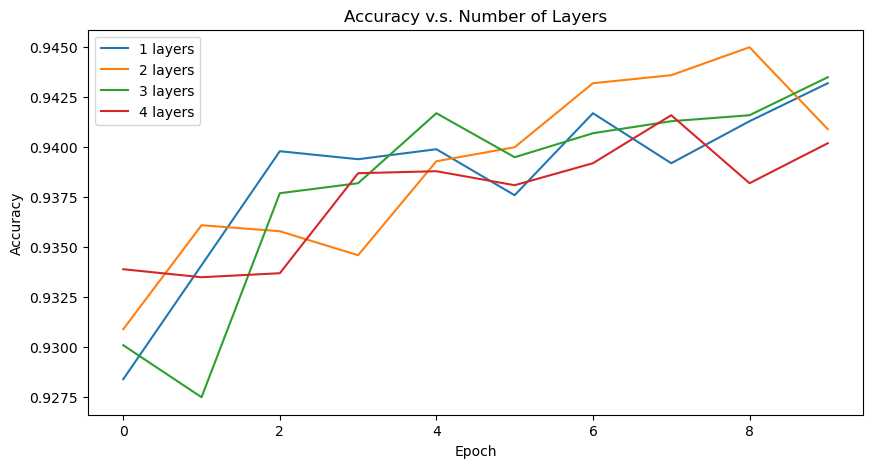

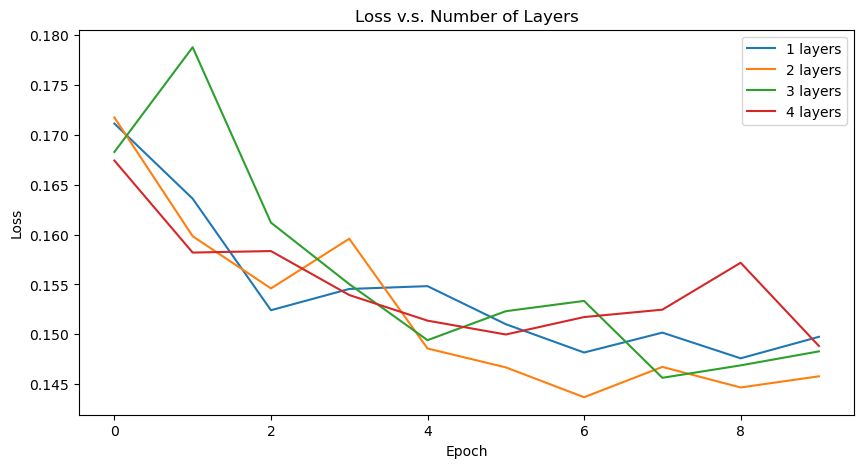

In [51]:
import matplotlib.pyplot as plt

# Plotting accuracy on testing data
plt.figure(figsize=(10, 5))
for name, history in history_dict.items():
    plt.plot(history.history['val_accuracy'], label=name)

plt.title('Accuracy v.s. Number of Layers')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='best')
plt.show()

# Plotting loss on testing data
plt.figure(figsize=(10, 5))
for name, history in history_dict.items():
    plt.plot(history.history['val_loss'], label=name)

plt.title('Loss v.s. Number of Layers')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(loc='best')
plt.show()

Training model with 1 layers
Training model with 2 layers
Training model with 3 layers
Training model with 4 layers
1 layers: Test Loss = 0.1533, Test Accuracy = 0.9388
2 layers: Test Loss = 0.1512, Test Accuracy = 0.9438
3 layers: Test Loss = 0.1483, Test Accuracy = 0.9390
4 layers: Test Loss = 0.1482, Test Accuracy = 0.9403


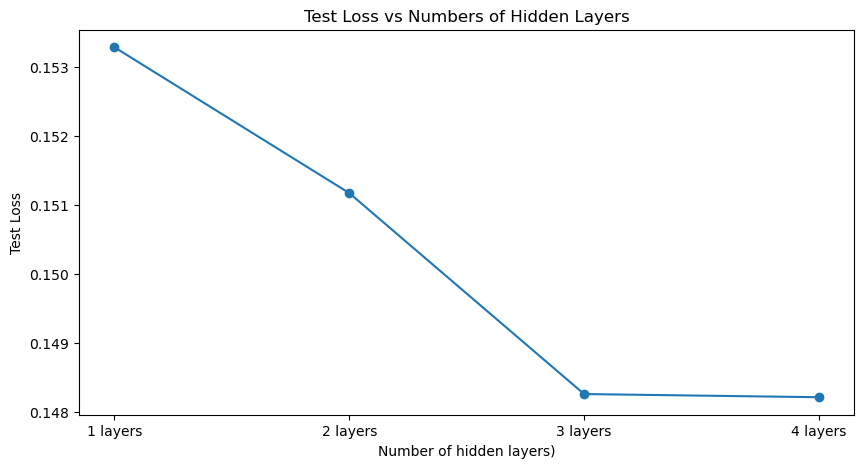

In [52]:
# Aadjust the labels
def adjust_labels(labels):
    new_labels = np.where((labels == 6) | (labels == 0) | (labels == 2) | (labels == 4), 0, labels)
    new_labels = np.where((new_labels == 1) | (new_labels == 3), 1, new_labels)
    new_labels = np.where((new_labels == 5) | (new_labels == 7) | (new_labels == 8) | (new_labels == 9), 2, new_labels)
    return new_labels

train_labels = adjust_labels(train_labels)
test_labels = adjust_labels(test_labels)

# Build models by increasing numbers of hidden layers
def create_multiclass_model(num_layers):
    model = Sequential([Flatten(input_shape=(28, 28))])
    for _ in range(num_layers):
        model.add(Dense(128, activation='relu'))
    model.add(Dense(3, activation='softmax'))
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Model Training
models = {f"{i} layers": create_multiclass_model(i) for i in range(1, 5)}

history_dict = {}
for name, model in models.items():
    print(f"Training model with {name}")
    history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels), verbose=0)
    history_dict[name] = history

# Model Evaluation
test_errors = {}
for name, model in models.items():
    test_loss, test_accuracy = model.evaluate(test_images, test_labels, verbose=0)
    test_errors[name] = test_loss
    print(f"{name}: Test Loss = {test_loss:.4f}, Test Accuracy = {test_accuracy:.4f}")

import matplotlib.pyplot as plt

# Plot the test losses for varying numbers of hidden layers
plt.figure(figsize=(10, 5))
plt.plot(list(test_errors.keys()), list(test_errors.values()), marker='o')
plt.title('Test Loss vs Numbers of Hidden Layers')
plt.xlabel('Number of hidden layers)')
plt.ylabel('Test Loss')
plt.show()

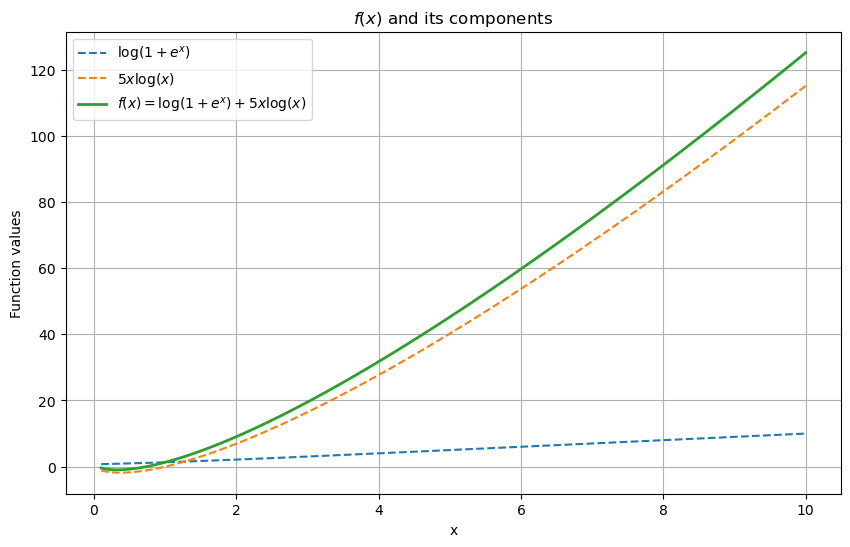

In [53]:
import numpy as np
import matplotlib.pyplot as plt

# The range of x values to be plotted
x_values = np.linspace(0.1, 10, 400)

# Define the components
w1 = np.exp(x_values)                 
w2 = 1 + w1                
w3 = np.log(w2)                 
w4 = np.log(x_values)            
w5 = 5 * x_values              
w6 = w5 * w4                         
f_x = w3 + w6                         

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(x_values, w3, label=r'$\log(1 + e^x)$', linestyle='--')
plt.plot(x_values, w6, label=r'$5x \log(x)$', linestyle='--')
plt.plot(x_values, f_x, label=r'$f(x) = \log(1 + e^x) + 5x \log(x)$', linewidth=2)
plt.title('$f(x)$ and its components')
plt.xlabel('x')
plt.ylabel('Function values')
plt.legend()
plt.grid(True)
plt.show()

In [54]:
import numpy as np
import tensorflow as tf

x = tf.Variable(10.0)

# Forward accumulation setup
with tf.autodiff.ForwardAccumulator(primals=x, tangents=tf.constant(1.0)) as acc:
    w1 = tf.exp(x)                
    w2 = 1 + w1                  
    w3 = tf.math.log(w2)         
    w4 = tf.math.log(x)   
    w5 = 5 * x                   
    w6 = w5 * w4     
    f = w3 + w6                   

# f'(x) at x = 10
df_dx = acc.jvp(f)

# Print the results
print('Function value (f(x)) at x = 10:', f.numpy())
print('Derivative of (f(x)) at x = 10:', df_dx.numpy())

Function value (f(x)) at x = 10: 125.1293
Derivative of (f(x)) at x = 10: 17.51288


In [55]:
import numpy as np
import tensorflow as tf

points = [1.0, 10.0, 50.0]

results = {}

for point in points:

    x = tf.Variable(point)

    with tf.GradientTape() as tape:
        w1 = tf.exp(x)                
        w2 = 1 + w1                  
        w3 = tf.math.log(w2)         
        w4 = tf.math.log(x)   
        w5 = 5 * x                   
        w6 = w5 * w4     
        f = w3 + w6 

    df_dx = tape.gradient(f, x)

    results[point] = {'Function Value': f.numpy(), 'Gradient': df_dx.numpy()}

# Print results for all points
for point, result in results.items():
    print(f"At x = {point}: Function Value = {result['Function Value']}, Gradient = {result['Gradient']}")

At x = 1.0: Function Value = 1.31326162815094, Gradient = 5.731058597564697
At x = 10.0: Function Value = 125.12930297851562, Gradient = 17.512880325317383
At x = 50.0: Function Value = 1028.0057373046875, Gradient = 25.560115814208984


In [56]:

x = tf.Variable(1.0)

learning_rate = 0.10

optimizer = tf.optimizers.SGD(learning_rate=learning_rate)

num_iterations = 1000

# Function to compute the function value
def compute_function(x):
        w1 = tf.exp(x)                
        w2 = 1 + w1                  
        w3 = tf.math.log(w2)         
        w4 = tf.math.log(x)   
        w5 = 5 * x                   
        w6 = w5 * w4     
        f = w3 + w6 
        return f

# Perform gradient descent
for iteration in range(num_iterations):
    with tf.GradientTape() as tape:
        
        f_val = compute_function(x)
    
    grad = tape.gradient(f_val, x)
    
    optimizer.apply_gradients([(grad, x)])

print(f"x^*: {x.numpy()}, f(x^*): {compute_function(x).numpy()}")

x^*: 0.3275119662284851, f(x^*): -0.9576429724693298
